# Chapitre 3 - Exercices 3.6 à 3.10

Interprétation bayésienne de ridge (3.6, 3.7), lien entre décomposition QR et SVD (3.8),
et mises en œuvre efficaces de la sélection pas à pas ascendante et descendante (3.9, 3.10).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import time
import pandas as pd
from scipy import stats
from esl import ch03_regression as cr

Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()

## Exercice 3.6 : Ridge comme moyenne a posteriori

**Énoncé.** Montrer que l'estimateur ridge est la moyenne (et le mode) de la loi a
posteriori de $\beta$ sous la loi a priori gaussienne $\beta \sim \mathcal{N}(0, \tau\mathbf{I})$
et le modèle d'échantillonnage gaussien $\mathbf{y} \sim \mathcal{N}(\mathbf{X}\beta, \sigma^2\mathbf{I})$.
Trouver la relation entre le paramètre $\lambda$ de ridge et les variances $\tau$ et $\sigma^2$.

**Rappels.**
- *Formule de Bayes* : la densité a posteriori est proportionnelle au produit
  vraisemblance × densité a priori : $\pi(\beta\mid\mathbf{y}) \propto p(\mathbf{y}\mid\beta)\,\pi(\beta)$
  (la constante ne dépend pas de $\beta$).
- Une densité de la forme $\propto \exp\bigl(-\tfrac12(\beta - m)^T\mathbf{P}(\beta - m)\bigr)$,
  $\mathbf{P}$ définie positive, est celle de $\mathcal{N}(m, \mathbf{P}^{-1})$ ; sa moyenne et son
  mode valent $m$.

On suppose (comme pour ridge) les entrées centrées et l'on omet la constante ; ici $\tau$
désigne une **variance**.

**Calcul.** Par Bayes,

$$
\pi(\beta\mid\mathbf{y}) \propto \exp\Bigl(-\frac{\lVert\mathbf{y} - \mathbf{X}\beta\rVert^2}{2\sigma^2}\Bigr)\exp\Bigl(-\frac{\lVert\beta\rVert^2}{2\tau}\Bigr)
 = \exp\Bigl(-\frac{1}{2\sigma^2}\Bigl[\lVert\mathbf{y} - \mathbf{X}\beta\rVert^2 + \frac{\sigma^2}{\tau}\lVert\beta\rVert^2\Bigr]\Bigr).
$$

Posons $\lambda = \sigma^2/\tau$ et développons le crochet :

$$
\beta^T(\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})\beta - 2\beta^T\mathbf{X}^T\mathbf{y} + \mathbf{y}^T\mathbf{y}.
$$

On **complète le carré** : avec $\mathbf{A} = \mathbf{X}^T\mathbf{X} + \lambda\mathbf{I}$ (définie
positive) et $m = \mathbf{A}^{-1}\mathbf{X}^T\mathbf{y}$,

$$
\beta^T\mathbf{A}\beta - 2\beta^T\mathbf{A}m = (\beta - m)^T\mathbf{A}(\beta - m) - m^T\mathbf{A}m .
$$

Le terme $m^T\mathbf{A}m$ et $\mathbf{y}^T\mathbf{y}$ ne dépendent pas de $\beta$ et partent dans
la constante. Donc

$$
\beta\mid\mathbf{y} \sim \mathcal{N}\bigl(m,\ \sigma^2\mathbf{A}^{-1}\bigr),\qquad
m = (\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^T\mathbf{y} = \hat\beta^{\mathrm{ridge}}
\quad\text{avec}\quad \boxed{\lambda = \sigma^2/\tau}.
$$

La loi a posteriori étant gaussienne, sa **moyenne** et son **mode** coïncident : tous deux
valent $\hat\beta^{\mathrm{ridge}}$. $\square$

> **Intuition.** Un a priori très diffus ($\tau \to \infty$) donne $\lambda \to 0$ : les
> moindres carrés. Un a priori resserré autour de 0 ($\tau$ petit) ou un bruit fort
> ($\sigma^2$ grand) poussent vers un fort rétrécissement.

**Vérification par Monte-Carlo.** Avec $p = 2$, on tire $\beta^{(b)}$ selon l'a priori et on
les pondère par la vraisemblance (échantillonnage d'importance) : la moyenne pondérée
approche la moyenne a posteriori.

In [2]:
rng = np.random.RandomState(0)
N, p, sigma, tau = 15, 2, 1.5, 0.5
X = rng.randn(N, p) @ np.array([[1.0, 0.7], [0.0, 0.7]])
X -= X.mean(0)
beta_true = rng.randn(p) * np.sqrt(tau)
y = X @ beta_true + sigma * rng.randn(N)
lam = sigma**2 / tau
beta_ridge = np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y)
draws = rng.randn(400000, p) * np.sqrt(tau)
loglik = -np.sum((y[None, :] - draws @ X.T) ** 2, axis=1) / (2 * sigma**2)
w = np.exp(loglik - loglik.max()); w /= w.sum()
post_mean = w @ draws
print("lambda = sigma^2/tau = %.2f" % lam)
print("moyenne a posteriori (Monte-Carlo) :", post_mean.round(3))
print("estimateur ridge                   :", beta_ridge.round(3))

lambda = sigma^2/tau = 4.50
moyenne a posteriori (Monte-Carlo) : [ 0.292 -0.104]
estimateur ridge                   : [ 0.292 -0.105]


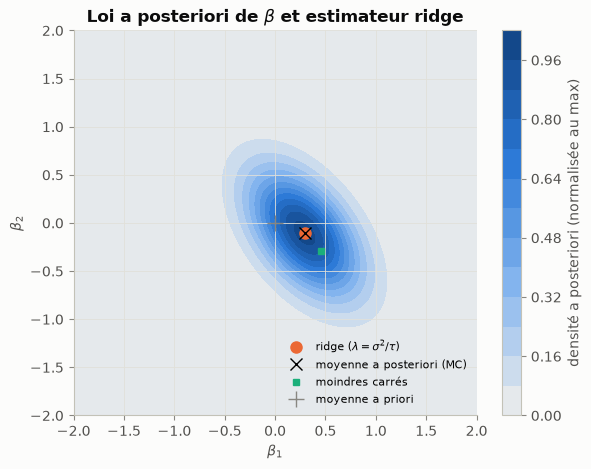

In [3]:
g1, g2 = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-2, 2, 300))
B = np.c_[g1.ravel(), g2.ravel()]
logpost = (-np.sum((y[None, :] - B @ X.T) ** 2, axis=1) / (2 * sigma**2)
           - np.sum(B**2, axis=1) / (2 * tau)).reshape(g1.shape)
beta_ls = np.linalg.lstsq(X, y, rcond=None)[0]
fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(g1, g2, np.exp(logpost - logpost.max()), levels=12, cmap=SEQ)
fig.colorbar(cs, ax=ax, label="densité a posteriori (normalisée au max)")
ax.plot(*beta_ridge, "o", color=ORANGE, markersize=8, label="ridge ($\\lambda=\\sigma^2/\\tau$)")
ax.plot(*post_mean, "x", color="black", markersize=9, label="moyenne a posteriori (MC)")
ax.plot(*beta_ls, "s", color=COLORS[2], label="moindres carrés")
ax.plot(0, 0, "+", color=GRAY, markersize=12, label="moyenne a priori")
ax.set_title("Loi a posteriori de $\\beta$ et estimateur ridge")
ax.set_xlabel(r"$\beta_1$"); ax.set_ylabel(r"$\beta_2$")
ax.legend(loc="lower right", fontsize=8)
plt.show()

Le mode (centre des contours), la moyenne Monte-Carlo et l'estimateur ridge coïncident ;
l'estimateur des moindres carrés est « tiré » vers la moyenne a priori 0.

> **À retenir.** Ridge = moyenne = mode a posteriori sous un a priori
> $\mathcal{N}(0, \tau\mathbf{I})$, avec $\lambda = \sigma^2/\tau$ (rapport variance du bruit /
> variance a priori).

## Exercice 3.7 : Log-vraisemblance a posteriori avec ordonnée à l'origine

**Énoncé.** On suppose $y_i \sim \mathcal{N}(\beta_0 + x_i^T\beta, \sigma^2)$, $i = 1..N$, et
les paramètres $\beta_j$, $j = 1..p$, indépendants de loi $\mathcal{N}(0, \tau^2)$. Avec
$\sigma^2$ et $\tau^2$ connus et $\beta_0$ sans loi a priori (ou avec une loi a priori plate
impropre), montrer que l'opposé du logarithme de la densité a posteriori est proportionnel
à $\sum_i(y_i - \beta_0 - \sum_jx_{ij}\beta_j)^2 + \lambda\sum_j\beta_j^2$, avec
$\lambda = \sigma^2/\tau^2$.

**Rappel (loi a priori plate impropre).** Donner à $\beta_0$ une « densité » constante sur
$\mathbb{R}$ revient à ne rien privilégier ; cette fonction n'est pas intégrable (d'où
« impropre »), mais la formule de Bayes reste utilisable tant que le produit
vraisemblance × a priori est intégrable en les paramètres, ce qui est le cas ici.

**Calcul.** Les observations étant indépendantes,
$p(\mathbf{y}\mid\beta_0, \beta) = \prod_i \frac{1}{\sqrt{2\pi}\sigma}\exp\bigl(-\frac{(y_i - \beta_0 - x_i^T\beta)^2}{2\sigma^2}\bigr)$,
et l'a priori vaut $\pi(\beta_0, \beta) \propto 1 \times \prod_j\exp\bigl(-\beta_j^2/(2\tau^2)\bigr)$.

En prenant $-\log$ du produit (les constantes de normalisation, qui ne dépendent pas des
paramètres, sont regroupées dans $C$) :

$$
\begin{aligned}
-\log\pi(\beta_0, \beta\mid\mathbf{y}) &= C + \frac{1}{2\sigma^2}\sum_{i=1}^N\Bigl(y_i - \beta_0 - \sum_j x_{ij}\beta_j\Bigr)^2 + \frac{1}{2\tau^2}\sum_{j=1}^p\beta_j^2 \\
&= C + \frac{1}{2\sigma^2}\Bigl[\sum_{i=1}^N\Bigl(y_i - \beta_0 - \sum_j x_{ij}\beta_j\Bigr)^2 + \frac{\sigma^2}{\tau^2}\sum_{j=1}^p\beta_j^2\Bigr].
\end{aligned}
$$

À la constante additive $C$ et au facteur $1/(2\sigma^2)$ près, c'est le critère ridge avec
$\lambda = \sigma^2/\tau^2$. Le maximum a posteriori est donc l'estimateur ridge (avec
$\beta_0$ non pénalisé, puisque sa loi a priori est plate). $\square$

> **Remarque.** L'exercice 3.6 notait $\tau$ la variance a priori ; ici c'est $\tau^2$,
> d'où $\lambda = \sigma^2/\tau$ là-bas et $\sigma^2/\tau^2$ ici : c'est la même relation.

**Vérification numérique.** On calcule $-\log$ (vraisemblance × a priori) avec `scipy.stats`
en des points $(\beta_0, \beta)$ aléatoires et l'on vérifie que la différence avec
$[\mathrm{RSS} + \lambda\lVert\beta\rVert^2]/(2\sigma^2)$ est **constante**.

In [4]:
rng = np.random.RandomState(1)
N, p, sigma, tau = 20, 3, 0.8, 1.3
X = rng.randn(N, p)
y = 1.0 + X @ rng.randn(p) + sigma * rng.randn(N)
lam = sigma**2 / tau**2
diffs = []
for _ in range(6):
    b0, b = rng.randn() * 3, rng.randn(p) * 2
    neg_log_post = -(stats.norm.logpdf(y, b0 + X @ b, sigma).sum() + stats.norm.logpdf(b, 0, tau).sum())
    ridge_crit = (np.sum((y - b0 - X @ b) ** 2) + lam * b @ b) / (2 * sigma**2)
    diffs.append(neg_log_post - ridge_crit)
print("différences (doivent être égales) :", np.round(diffs, 10))

différences (doivent être égales) : [17.45980803 17.45980803 17.45980803 17.45980803 17.45980803 17.45980803]


> **À retenir.** $-\log$ a posteriori $= C + \frac{1}{2\sigma^2}\bigl[\mathrm{RSS} + \lambda\lVert\beta\rVert^2\bigr]$,
> $\lambda = \sigma^2/\tau^2$ ; une loi a priori plate sur $\beta_0$ correspond à ne pas
> pénaliser l'ordonnée à l'origine.

## Exercice 3.8 : Décomposition QR et SVD

**Énoncé.** Soit la décomposition QR de la matrice **non centrée** $\mathbf{X}$ de taille
$N\times(p+1)$ (première colonne de uns), et la SVD $\tilde{\mathbf{X}} = \mathbf{U}\mathbf{D}\mathbf{V}^T$
de la matrice **centrée** $\tilde{\mathbf{X}}$ ($N\times p$). Montrer que $\mathbf{Q}_2$
(la matrice $\mathbf{Q}$ privée de sa première colonne) et $\mathbf{U}$ engendrent le même
sous-espace. Dans quelles circonstances sont-elles égales, aux signes près ?

**Rappels.** Dans la QR obtenue par Gram–Schmidt, pour tout $j$,
$\mathrm{vect}(\mathbf{q}_0, \dots, \mathbf{q}_j) = \mathrm{vect}(\mathbf{x}_0, \dots, \mathbf{x}_j)$,
et $\mathbf{q}_0 = \mathbf{1}/\sqrt N$. Dans la SVD (avec $\mathbf{D}$ inversible si
$\tilde{\mathbf{X}}$ est de rang $p$), $\mathrm{col}(\tilde{\mathbf{X}}) = \mathrm{col}(\mathbf{U})$
car $\tilde{\mathbf{X}} = \mathbf{U}(\mathbf{D}\mathbf{V}^T)$ et $\mathbf{U} = \tilde{\mathbf{X}}\mathbf{V}\mathbf{D}^{-1}$.

**Même sous-espace.** Notons $E = \mathrm{vect}(\mathbf{1}, \mathbf{x}_1, \dots, \mathbf{x}_p) = \mathrm{col}(\mathbf{X})$.
- Les $\mathbf{q}_j$, $j \ge 1$, sont dans $E$ et orthogonaux à $\mathbf{q}_0 \propto \mathbf{1}$ :
  $\mathrm{col}(\mathbf{Q}_2) \subset E \cap \mathbf{1}^\perp$.
- Les $\tilde{\mathbf{x}}_j = \mathbf{x}_j - \bar x_j\mathbf{1}$ sont dans $E$ et orthogonaux à
  $\mathbf{1}$ (leur somme est nulle) : $\mathrm{col}(\tilde{\mathbf{X}}) \subset E \cap \mathbf{1}^\perp$.
- $E \cap \mathbf{1}^\perp$ est de dimension $(p+1) - 1 = p$ (on retire la direction
  $\mathbf{1} \in E$), et les deux sous-espaces précédents sont aussi de dimension $p$
  (colonnes indépendantes).

Donc $\mathrm{col}(\mathbf{Q}_2) = E \cap \mathbf{1}^\perp = \mathrm{col}(\tilde{\mathbf{X}}) = \mathrm{col}(\mathbf{U})$. $\square$

**Égalité aux signes près.** Remarquons d'abord que $\mathbf{Q}_2$ est aussi le facteur
$\mathbf{Q}$ de Gram–Schmidt appliqué à $\tilde{\mathbf{X}}$ : orthogonaliser $\mathbf{x}_j$
contre $\mathbf{q}_0$ revient à le centrer. Ainsi $\tilde{\mathbf{X}} = \mathbf{Q}_2\mathbf{R}_2$
avec $\mathbf{R}_2$ triangulaire supérieure à diagonale $> 0$.

Supposons $\mathbf{Q}_2 = \mathbf{U}\mathbf{S}$ avec $\mathbf{S} = \mathrm{diag}(\pm1)$. Alors
$\mathbf{U}\mathbf{D}\mathbf{V}^T = \mathbf{U}\mathbf{S}\mathbf{R}_2$, et en multipliant à
gauche par $\mathbf{U}^T$ : $\mathbf{V}^T = \mathbf{D}^{-1}\mathbf{S}\mathbf{R}_2$, qui est
**triangulaire supérieure**.

Or une matrice orthogonale triangulaire supérieure est diagonale : son inverse
$\mathbf{V}$ est à la fois triangulaire supérieure (inverse d'une triangulaire supérieure)
et inférieure (transposée d'une triangulaire supérieure). Donc $\mathbf{V} = \mathrm{diag}(\pm1)$
et

$$
\tilde{\mathbf{X}}^T\tilde{\mathbf{X}} = \mathbf{V}\mathbf{D}^2\mathbf{V}^T = \mathbf{D}^2 \text{ est diagonale.}
$$

**Conclusion.** $\mathbf{Q}_2 = \mathbf{U}$ aux signes près si et seulement si les colonnes
**centrées** sont deux à deux **orthogonales** (variables non corrélées) **et rangées par
norme décroissante** $\lVert\tilde{\mathbf{x}}_1\rVert \ge \dots \ge \lVert\tilde{\mathbf{x}}_p\rVert$
(puisque les $d_j$ sont rangés par ordre décroissant). Réciproquement, dans ce cas
Gram–Schmidt ne fait que normaliser : $\mathbf{q}_j = \tilde{\mathbf{x}}_j/\lVert\tilde{\mathbf{x}}_j\rVert$,
qui sont des vecteurs singuliers à gauche (uniques au signe près si les normes sont
distinctes). Si les colonnes sont orthogonales mais dans un autre ordre, l'égalité vaut à
une **permutation** près.

**Vérification numérique.** On compare les projecteurs $\mathbf{Q}_2\mathbf{Q}_2^T$ et
$\mathbf{U}\mathbf{U}^T$ (égaux ssi même sous-espace), puis la matrice $\mathbf{Q}_2^T\mathbf{U}$
(diagonale de $\pm1$ ssi égalité aux signes près).

In [5]:
def compare_qr_svd(X):
    Q, _ = np.linalg.qr(cr.add_intercept(X))
    Q2 = Q[:, 1:]
    U = np.linalg.svd(X - X.mean(0), full_matrices=False)[0]
    return np.abs(Q2 @ Q2.T - U @ U.T).max(), np.abs(Q2.T @ U)


rng = np.random.RandomState(0)
X_gen = rng.randn(30, 3) @ rng.randn(3, 3)                 # cas général
ecart, M = compare_qr_svd(X_gen)
print("cas général : écart des projecteurs = %.1e" % ecart)
print("|Q2^T U| =\n", M.round(3))

cas général : écart des projecteurs = 1.1e-15
|Q2^T U| =
 [[0.012 0.992 0.123]
 [1.    0.014 0.022]
 [0.024 0.123 0.992]]


In [6]:
Qo = np.linalg.qr(rng.randn(30, 3) - rng.randn(30, 3).mean(0))[0]
Qo = Qo - Qo.mean(0)
Qo = np.linalg.qr(np.c_[np.ones(30), Qo])[0][:, 1:]       # colonnes centrées orthonormées
X_orth = Qo * [5.0, 3.0, 1.0] + [2.0, -1.0, 7.0]           # orthogonales, normes décroissantes
print("colonnes centrées orthogonales, normes décroissantes : |Q2^T U| =\n", compare_qr_svd(X_orth)[1].round(3))
print("même chose, normes dans le désordre : |Q2^T U| =\n", compare_qr_svd(X_orth[:, [1, 2, 0]])[1].round(3))

colonnes centrées orthogonales, normes décroissantes : |Q2^T U| =
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
même chose, normes dans le désordre : |Q2^T U| =
 [[0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


Dans le cas général, $\mathbf{Q}_2^T\mathbf{U}$ est une matrice orthogonale quelconque
(même sous-espace, bases différentes). Dans le cas orthogonal ordonné, c'est l'identité au
signe près ; dans le désordre, une matrice de permutation.

> **À retenir.** QR (non centrée, sans la première colonne) et SVD (centrée) engendrent
> toutes deux l'espace des colonnes centrées ; elles coïncident (au signe près) seulement
> pour des variables non corrélées rangées par variance décroissante.

## Exercice 3.9 : Sélection pas à pas ascendante efficace

**Énoncé.** On dispose de la décomposition QR de la matrice $\mathbf{X}_1$ ($N\times q$) d'une
régression multiple de réponse $\mathbf{y}$, et de $p - q$ prédicteurs supplémentaires dans
$\mathbf{X}_2$. Soit $\mathbf{r}$ le résidu courant. On veut savoir laquelle de ces variables
supplémentaires, ajoutée à celles de $\mathbf{X}_1$, fait le plus baisser le RSS. Décrire une
procédure efficace.

**Analyse.** Soit $\mathbf{X}_1 = \mathbf{Q}\mathbf{R}$, et $\mathbf{r} = \mathbf{y} - \mathbf{Q}\mathbf{Q}^T\mathbf{y}$,
orthogonal à $\mathrm{col}(\mathbf{Q})$. Pour une candidate $\mathbf{x}_j$ (colonne de
$\mathbf{X}_2$), décomposons

$$
\mathbf{x}_j = \mathbf{Q}\mathbf{Q}^T\mathbf{x}_j + \mathbf{e}_j,\qquad \mathbf{e}_j \perp \mathrm{col}(\mathbf{Q}).
$$

Alors $\mathrm{col}([\mathbf{X}_1, \mathbf{x}_j]) = \mathrm{col}(\mathbf{Q}) \oplus \mathrm{vect}(\mathbf{e}_j)$
(somme orthogonale), et, comme à l'exercice 3.1, le nouveau RSS vaut

$$
\mathrm{RSS}_j = \mathrm{RSS} - \frac{\langle\mathbf{e}_j, \mathbf{y}\rangle^2}{\lVert\mathbf{e}_j\rVert^2}
 = \mathrm{RSS} - \frac{\langle\mathbf{x}_j, \mathbf{r}\rangle^2}{\lVert\mathbf{x}_j\rVert^2 - \lVert\mathbf{Q}^T\mathbf{x}_j\rVert^2},
$$

car $\langle\mathbf{e}_j, \mathbf{y}\rangle = \langle\mathbf{e}_j, \mathbf{r}\rangle = \langle\mathbf{x}_j, \mathbf{r}\rangle$
($\mathbf{r}$ et $\mathbf{e}_j$ sont orthogonaux à $\mathrm{col}(\mathbf{Q})$) et, par Pythagore,
$\lVert\mathbf{e}_j\rVert^2 = \lVert\mathbf{x}_j\rVert^2 - \lVert\mathbf{Q}^T\mathbf{x}_j\rVert^2$.

**Procédure.**
1. Calculer $\mathbf{X}_2^T\mathbf{r}$ (coût $O(N(p-q))$) et $\mathbf{Q}^T\mathbf{X}_2$
   (coût $O(Nq(p-q))$), d'où $\lVert\mathbf{e}_j\rVert^2$ pour toutes les candidates.
2. Choisir $j^\star = \arg\max_j \langle\mathbf{x}_j, \mathbf{r}\rangle^2/\lVert\mathbf{e}_j\rVert^2$.
3. **Mettre à jour** sans tout recalculer : $\mathbf{q}_{\text{new}} = \mathbf{e}_{j^\star}/\lVert\mathbf{e}_{j^\star}\rVert$
   (une étape de Gram–Schmidt), $\mathbf{r} \leftarrow \mathbf{r} - \langle\mathbf{q}_{\text{new}}, \mathbf{r}\rangle\mathbf{q}_{\text{new}}$,
   et l'on ajoute la ligne $\mathbf{q}_{\text{new}}^T\mathbf{X}_2$ à $\mathbf{Q}^T\mathbf{X}_2$
   (coût $O(N(p-q))$). La matrice $\mathbf{R}$ s'étend d'une colonne.

On évite ainsi de refaire $p - q$ régressions complètes (coût $O(Nq^2)$ chacune).

> **Interprétation.** $\langle\mathbf{x}_j, \mathbf{r}\rangle^2/(\lVert\mathbf{e}_j\rVert^2\lVert\mathbf{r}\rVert^2)$
> est le carré de la **corrélation partielle** entre $\mathbf{y}$ et $\mathbf{x}_j$ ajustés pour
> $\mathbf{X}_1$ : on choisit la variable de plus forte corrélation partielle (cf. exercice 3.26).

Implémentation (une étape) et comparaison avec la méthode naïve :

In [7]:
def best_addition(Q, r, X2):
    """Indice de la colonne de X2 qui réduit le plus le RSS, et les réductions."""
    QtX2 = Q.T @ X2
    e2 = np.sum(X2**2, axis=0) - np.sum(QtX2**2, axis=0)
    gain = (X2.T @ r) ** 2 / e2
    return int(np.argmax(gain)), gain


rng = np.random.RandomState(0)
N, q, p_tot = 500, 20, 220
Xall = rng.randn(N, p_tot) @ (np.eye(p_tot) + 0.1 * rng.randn(p_tot, p_tot))
yall = Xall[:, :30] @ rng.randn(30) + rng.randn(N)
X1, X2 = cr.add_intercept(Xall[:, :q]), Xall[:, q:]
Q, R = np.linalg.qr(X1)
r = yall - Q @ (Q.T @ yall)
rss = r @ r
t0 = time.perf_counter()
j_fast, gain = best_addition(Q, r, X2)
t_fast = time.perf_counter() - t0
t0 = time.perf_counter()
rss_naive = [np.sum((yall - np.c_[X1, X2[:, j]] @ np.linalg.lstsq(np.c_[X1, X2[:, j]], yall, rcond=None)[0]) ** 2)
             for j in range(X2.shape[1])]
t_naive = time.perf_counter() - t0
print("candidate choisie : rapide = %d, naïve = %d" % (j_fast, int(np.argmin(rss_naive))))
print("écart max des RSS : %.1e" % np.abs(rss - gain - np.array(rss_naive)).max())
print("temps : rapide = %.4f s, naïf = %.4f s" % (t_fast, t_naive))

candidate choisie : rapide = 0, naïve = 0
écart max des RSS : 2.7e-12
temps : rapide = 0.0005 s, naïf = 0.0445 s


Le module `esl.ch03_regression` contient la procédure complète (`forward_stepwise`), qui
enchaîne ces étapes avec la mise à jour de $\mathbf{Q}$. Sur la prostate :

In [8]:
order, rss_path = cr.forward_stepwise(Xtr, ytr)
pd.DataFrame({"variable ajoutée": ["(constante)"] + [names[j] for j in order], "RSS": rss_path}).round(3)

,variable ajoutée,RSS
0,(constante),96.281
1,lcavol,44.529
2,lweight,37.092
3,svi,34.908
4,lbph,32.815
5,pgg45,32.069
6,lcp,30.540
7,age,29.437
8,gleason,29.426


> **À retenir.** Avec la QR courante, la baisse de RSS pour la candidate $j$ vaut
> $\langle\mathbf{x}_j, \mathbf{r}\rangle^2/\lVert\mathbf{e}_j\rVert^2$ ; une étape de
> Gram–Schmidt met ensuite la base à jour.

## Exercice 3.10 : Sélection pas à pas descendante

**Énoncé.** On dispose de l'ajustement de la régression multiple de $\mathbf{y}$ sur
$\mathbf{X}$, avec erreurs standard et scores $Z$ comme au tableau 3.2. On veut trouver la
variable dont le retrait augmente **le moins** le RSS. Comment faire ?